# 方板受压：正则化变量投影与自动源点比例优化

本版替换旧的Adam联合更新流程。KM点力核、物理条件和边界配置保持相同；采用双精度、消除复势常数项的等价自由度，并加入明确的Tikhonov正则化。每个候选alpha均重新拟合核权重，按边界验证残差自动括定并连续优化。

**不使用参考场选择alpha；不预设1.2为目标。** 自动括定仍需多次函数评价，耗时包含这些评价，不能称为不需要搜索。固定组和自适应组采用相同精度与正则化。

默认参考为原笔记本BEM，只需numpy、scipy、matplotlib；PyTorch不再是此训练策略的必需依赖。若已有BEM的internal_pts/u_int/von_mises，可跳过下面BEM单元。可改用COMSOL八列数据。

独立源点优化参数：24源点/边，200训练点/边，257中点验证点/边，alpha范围[1.02,1.50]，正则化相对尺度1e-8，13点自动括定，连续优化容差2e-5。198个独立实系数加1个比例参数。


## BEM参考解（原算法的NumPy向量化实现，800个常数边界单元）


In [1]:
import numpy as np
from scipy.linalg import solve
import time
from pathlib import Path
try:
    from threadpoolctl import threadpool_limits
    threadpool_limits(1)
except ImportError:
    pass
L=1.;E=1e6;nu=.3;disp_top=-1e-4;n=200;N=4*n;G=E/(2*(1+nu))
t=np.linspace(L/(2*n),L-L/(2*n),n)
nodes=np.vstack([np.c_[t,0*t],np.c_[0*t+L,t],np.c_[t[::-1],0*t+L],np.c_[0*t,t[::-1]]])
normals=np.repeat([[0,-1],[1,0],[0,1],[-1,0]],n,axis=0).astype(float)
tx=-normals[:,1];ty=normals[:,0];nx=normals[:,0][None,:];ny=normals[:,1][None,:]
length=L/n;C1=1/(8*np.pi*G*(1-nu));C2=3-4*nu;C3=-1/(4*np.pi*(1-nu));C4=1-2*nu
xi,w=np.polynomial.legendre.leggauss(4)
def kernels(points):
 U=[np.zeros((len(points),N)) for _ in range(4)];T=[np.zeros_like(U[0]) for _ in range(4)]
 for g in range(4):
  rx=nodes[:,0][None,:]+.5*length*xi[g]*tx[None,:]-points[:,0,None]
  ry=nodes[:,1][None,:]+.5*length*xi[g]*ty[None,:]-points[:,1,None]
  r=np.hypot(rx,ry);dx=rx/r;dy=ry/r;dn=dx*nx+dy*ny;hw=.5*length*w[g]
  U[0]+=C1*(C2*np.log(1/r)+dx*dx)*hw
  U[1]+=C1*dx*dy*hw;U[2]+=C1*dx*dy*hw
  U[3]+=C1*(C2*np.log(1/r)+dy*dy)*hw
  T[0]+=C3/r*dn*(C4+2*dx*dx)*hw
  T[1]+=C3/r*(dn*2*dx*dy-C4*(dx*ny-dy*nx))*hw
  T[2]+=C3/r*(dn*2*dy*dx-C4*(dy*nx-dx*ny))*hw
  T[3]+=C3/r*dn*(C4+2*dy*dy)*hw
 return U,T
start=time.perf_counter();U,T=kernels(nodes)
for a in T: np.fill_diagonal(a,0)
np.fill_diagonal(T[0],.5);np.fill_diagonal(T[3],.5)
g00=C1*length*(C2*(1-np.log(length/2))+1);g11=C1*length*C2*(1-np.log(length/2))
np.fill_diagonal(U[0],g00*tx**2+g11*normals[:,0]**2)
np.fill_diagonal(U[1],g00*tx*ty+g11*normals[:,0]*normals[:,1]);np.fill_diagonal(U[2],U[1].diagonal())
np.fill_diagonal(U[3],g00*ty**2+g11*normals[:,1]**2)
HH=np.empty((2*N,2*N));GG=np.empty_like(HH)
for i in range(2):
 for j in range(2): HH[i::2,j::2]=T[2*i+j];GG[i::2,j::2]=U[2*i+j]
known_node=np.repeat([True,False,True,False],n);known=np.repeat(known_node,2)
ub=np.zeros(2*N);ub[4*n+1:6*n:2]=disp_top
A=HH.copy();A[:,known]=-GG[:,known]
rhs=-HH@ub
X=solve(A,rhs,check_finite=False)
tb=np.zeros(2*N);tb[known]=X[known];ub[~known]=X[~known]
print('BEM solve',time.perf_counter()-start,flush=True)
def internal_u(pts):
 out=[]
 for i in range(0,len(pts),128):
  U,T=kernels(pts[i:i+128])
  ux=U[0]@tb[::2]+U[1]@tb[1::2]-T[0]@ub[::2]-T[1]@ub[1::2]
  uy=U[2]@tb[::2]+U[3]@tb[1::2]-T[2]@ub[::2]-T[3]@ub[1::2]
  out.append(np.c_[ux,uy])
 return np.vstack(out)
grid=np.linspace(.02,.98,200);xx,yy=np.meshgrid(grid,grid);pts=np.c_[xx.ravel(),yy.ravel()]
u0=internal_u(pts);print('internal displacement',time.perf_counter()-start,flush=True)
delta=1e-4
dx=(internal_u(pts+[delta,0])-internal_u(pts-[delta,0]))/(2*delta)
print('dx',time.perf_counter()-start,flush=True)
dy=(internal_u(pts+[0,delta])-internal_u(pts-[0,delta]))/(2*delta)
lam=E*nu/((1+nu)*(1-2*nu));sxx=lam*(dx[:,0]+dy[:,1])+2*G*dx[:,0];syy=lam*(dx[:,0]+dy[:,1])+2*G*dy[:,1];sxy=G*(dx[:,1]+dy[:,0]);szz=nu*(sxx+syy)
vm=np.sqrt(.5*((sxx-syy)**2+(syy-szz)**2+(szz-sxx)**2)+3*sxy**2)
bem_output_dir = Path.cwd() / 'adaptive_source_results'
bem_output_dir.mkdir(parents=True, exist_ok=True)
np.savez(bem_output_dir / 'bem_reference.npz',points=pts,ux=u0[:,0],uy=u0[:,1],sxx=sxx,syy=syy,sxy=sxy,von_mises=vm)
print('Reference complete',time.perf_counter()-start,flush=True)

internal_pts = pts
u_int = u0
von_mises = vm


BEM solve 0.7583501999615692
internal displacement 8.410874099994544
dx 22.02280569996219
Reference complete 35.6809254999971


## 双精度KM核与自动比例优化

In [2]:
# -*- coding: utf-8 -*-
"""KM点力核方板：双精度、正则化变量投影与自动源点比例优化。

独立运行只需 numpy/scipy/matplotlib，不依赖 PyTorch 或参考解。
源点优化不接收 BEM/COMSOL 场标签，参考解只用于最后的误差评价。
算法是核网络线性权重的最小二乘训练 + 一个非线性源点比例的有界优化，
不是 Adam 联合训练。全区间自动括定会进行多次目标函数计算，计入耗时。
"""
from pathlib import Path
import csv
import json
import time
import numpy as np
from scipy.linalg import svd
from scipy.optimize import minimize_scalar

L = 1.0
E_REAL = 1.0e6
NU = 0.3
DISP_TOP_REAL = -1.0e-4
SCALE_U = 1.0e4
E = 1.0
G = E / (2.0 * (1.0 + NU))
KAPPA = 3.0 - 4.0 * NU
DISP_TOP = DISP_TOP_REAL * SCALE_U
N_SOURCES_PER_SIDE = 24
N_BOUNDARY_PER_EDGE = 200
N_VALIDATION_PER_EDGE = 257
ALPHA_BOUNDS = (1.02, 1.50)
FIXED_ALPHA_VALUES = (1.05, 1.10, 1.20, 1.30, 1.40)
ADAPTIVE_ALPHA_INITIALS = (1.05, 1.20, 1.40)
# 相对最大奇异值的平滑Tikhonov滤波尺度。
# 固定与自适应组共用；不能利用参考场误差调到某个期望alpha。
REGULARIZATION_REL = 1.0e-8
BRACKET_POINTS = 13
ALPHA_XTOL = 2.0e-5
SHOW_FIGURES = True


def source_points(alpha, n_per_side=N_SOURCES_PER_SIDE):
    if not (np.isfinite(alpha) and alpha > 1):
        raise ValueError("alpha必须为大于1的有限数。")
    half = 0.5 * L * alpha
    lo, hi = 0.5 * L - half, 0.5 * L + half
    t = np.linspace(lo, hi, n_per_side + 2, dtype=np.float64)[1:-1]
    return np.vstack((np.column_stack((t, np.full_like(t, lo))),
                      np.column_stack((np.full_like(t, hi), t)),
                      np.column_stack((t[::-1], np.full_like(t, hi))),
                      np.column_stack((np.full_like(t, lo), t[::-1]))))


def boundary_points(n, midpoint=False):
    # validation采用单元中点网格；与原等分内部训练点采用不同采样规则。
    t = L * ((np.arange(n) + 0.5) / n if midpoint
             else np.arange(1, n + 1) / (n + 1))
    return {"bottom": np.column_stack((t, np.zeros_like(t))),
            "top": np.column_stack((t, np.full_like(t, L))),
            "left": np.column_stack((np.zeros_like(t), t)),
            "right": np.column_stack((np.full_like(t, L), t))}


def potential_cache(points, sources):
    points = np.asarray(points, dtype=np.float64)
    z = points[:, 0] + 1j * points[:, 1]
    s = sources[:, 0] + 1j * sources[:, 1]
    dz = z[:, None] - s[None, :]
    angle = np.angle(0.5 * L * (1 + 1j) - s)
    rotated = dz * np.exp(-1j * angle[None, :])
    scale = np.sqrt(len(s))
    return {"z": z,
            "basis": (np.log(np.abs(rotated)) + 1j * (
                np.angle(rotated) + angle[None, :])) / scale,
            "d1": 1.0 / dz / scale, "d2": -1.0 / dz**2 / scale,
            "sbar": np.conj(s), "n": len(s)}


def fields_from_coefficients(coeff, cache):
    """接受一个系数向量或多个列向量，均使用原KM点力核公式。"""
    coeff = np.asarray(coeff, dtype=np.float64)
    n = cache["n"]
    z = cache["z"][:, None] if coeff.ndim == 2 else cache["z"]
    p = coeff[:n] + 1j * coeff[n:2*n]
    phi0 = coeff[2*n] + 1j * coeff[2*n+1]
    phi1 = coeff[2*n+2] + 1j * coeff[2*n+3]
    psi0 = coeff[2*n+4] + 1j * coeff[2*n+5]
    psi1 = coeff[2*n+6] + 1j * coeff[2*n+7]
    b, d1, d2 = cache["basis"], cache["d1"], cache["d2"]
    cf = 1.0 / (2.0 * np.pi * (KAPPA + 1.0))
    phi = -cf * (b @ p) + phi0 + phi1 * z
    dphi = -cf * (d1 @ p) + phi1
    d2phi = -cf * (d2 @ p)
    psi = cf * (KAPPA * (b @ np.conj(p)) +
                (d1 * cache["sbar"][None, :]) @ p) + psi0 + psi1*z
    dpsi = cf * (KAPPA * (d1 @ np.conj(p)) +
                 (d2 * cache["sbar"][None, :]) @ p) + psi1
    u = (KAPPA*phi - z*np.conj(dphi) - np.conj(psi))/(2*G)
    total = 4*dphi.real
    difference = 2*(np.conj(z)*d2phi + dpsi)
    return u.real, u.imag, 0.5*(total-difference.real), \
        0.5*(total+difference.real), 0.5*difference.imag


def boundary_matrix(alpha, n_points, n_sources=N_SOURCES_PER_SIDE, midpoint=False):
    sources = source_points(alpha, n_sources)
    n = len(sources)
    # 原表示中的phi0/psi0包含2个等价常数自由度。
    # 固定psi0=0消除规范冗余，并不改变可表示的位移和应力场。
    active = np.delete(np.arange(2*n+8), [2*n+4, 2*n+5])
    identity = np.eye(2*n+8, dtype=np.float64)[:, active]
    sides = boundary_points(n_points, midpoint)
    f = {k: fields_from_coefficients(identity, potential_cache(v, sources))
         for k, v in sides.items()}
    matrix = np.vstack((f["bottom"][0], f["bottom"][1],
                        f["top"][0], f["top"][1],
                        f["left"][2], f["left"][4],
                        f["right"][2], f["right"][4]))
    rhs = np.zeros(8*n_points, dtype=np.float64)
    rhs[3*n_points:4*n_points] = DISP_TOP
    return matrix, rhs, active


def fit_at_alpha(alpha, regularization_rel=REGULARIZATION_REL,
                 n_train=N_BOUNDARY_PER_EDGE, n_validation=N_VALIDATION_PER_EDGE,
                 n_sources=N_SOURCES_PER_SIDE):
    """每个alpha重新拟合线性系数；不使用任何参考解。"""
    a, b, active = boundary_matrix(alpha, n_train, n_sources)
    u, s, vt = svd(a, full_matrices=False, lapack_driver="gesdd")
    tau = regularization_rel * s[0]
    if regularization_rel > 0:
        weights = s / (s*s + tau*tau)
    else:
        cutoff = np.finfo(float).eps * max(a.shape) * s[0]
        weights = np.divide(1.0, s, out=np.zeros_like(s), where=s > cutoff)
    reduced = vt.T @ (weights * (u.T @ b))
    coeff = np.zeros(2*4*n_sources+8)
    coeff[active] = reduced
    av, bv, _ = boundary_matrix(alpha, n_validation, n_sources, midpoint=True)
    train_loss = float(np.sum((a @ reduced-b)**2)/n_train)
    validation_loss = float(np.sum((av @ reduced-bv)**2)/n_validation)
    kept = s > max(tau, np.finfo(float).eps*max(a.shape)*s[0])
    return {"alpha": float(alpha), "coefficients": coeff,
            "n_sources_per_side": int(n_sources),
            "train_loss": train_loss, "validation_loss": validation_loss,
            "coefficient_norm": float(np.linalg.norm(reduced)),
            "effective_rank": int(np.count_nonzero(kept)),
            "effective_condition": float(s[0]/s[kept][-1]),
            "regularization_rel": float(regularization_rel)}


def optimize_source_scale(alpha_initial, bounds=ALPHA_BOUNDS,
                          bracket_points=BRACKET_POINTS,
                          regularization_rel=REGULARIZATION_REL,
                          n_sources=N_SOURCES_PER_SIDE,
                          n_train=N_BOUNDARY_PER_EDGE,
                          n_validation=N_VALIDATION_PER_EDGE):
    """全区间自动括定 + 每个可见低谷内连续优化，返回真正计算到的最优。

    全区间探索为降低初值依赖提供保障，不宣称数学上的全局最优。
    不同运行不共享缓存；每行耗时都包含完整搜索成本。
    """
    lo, hi = map(float, bounds)
    if not (1 < lo < hi and lo <= alpha_initial <= hi):
        raise ValueError("需要1<lower<upper且初值位于允许范围内。")
    cache, history = {}, []
    start = time.perf_counter()

    def evaluate(alpha):
        alpha = float(alpha)
        if alpha not in cache:
            fit = fit_at_alpha(alpha, regularization_rel, n_train,
                               n_validation, n_sources)
            cache[alpha] = fit
            history.append({k: fit[k] for k in ["alpha", "train_loss",
                "validation_loss", "coefficient_norm", "effective_rank"]})
        return cache[alpha]["validation_loss"]

    evaluate(alpha_initial)
    grid = np.linspace(lo, hi, bracket_points)
    values = np.array([evaluate(a) for a in grid])
    intervals = []
    for i in range(1, len(grid)-1):
        if values[i] <= values[i-1] and values[i] <= values[i+1]:
            intervals.append((grid[i-1], grid[i+1]))
    if values[0] <= values[1]:
        intervals.append((grid[0], grid[1]))
    if values[-1] <= values[-2]:
        intervals.append((grid[-2], grid[-1]))
    for interval in intervals:
        result = minimize_scalar(lambda a: np.log(max(evaluate(a), 1e-300)),
            bounds=interval, method="bounded",
            options={"xatol": ALPHA_XTOL, "maxiter": 80})
        evaluate(result.x)
    best = min(cache.values(), key=lambda f: f["validation_loss"])
    best = dict(best)
    best.update(alpha_initial=float(alpha_initial),
                search_time_s=time.perf_counter()-start,
                objective_evaluations=len(cache), history=history,
                selection_objective="boundary_validation_loss",
                algorithm="regularized_variable_projection_auto_bracketing")
    return best


def predict_fields(result, points, batch_size=2000):
    sources = source_points(result["alpha"], result.get("n_sources_per_side", N_SOURCES_PER_SIDE))
    chunks = [[] for _ in range(5)]
    for i in range(0, len(points), batch_size):
        f = fields_from_coefficients(result["coefficients"],
                                    potential_cache(points[i:i+batch_size], sources))
        for bucket, values in zip(chunks, f):
            bucket.append(values)
    ux, uy, sxx, syy, sxy = [np.concatenate(v) for v in chunks]
    ux, uy = ux/SCALE_U, uy/SCALE_U
    scale = E_REAL/SCALE_U
    sxx, syy, sxy = sxx*scale, syy*scale, sxy*scale
    szz = NU*(sxx+syy)
    vm = np.sqrt(0.5*((sxx-syy)**2+(syy-szz)**2+(szz-sxx)**2)+3*sxy**2)
    return dict(ux=ux, uy=uy, sxx=sxx, syy=syy, sxy=sxy, von_mises=vm)


def relative_l2(pred, reference):
    return float(np.linalg.norm(pred-reference)/max(np.linalg.norm(reference), 1e-30))


def evaluate_reference(result, points, reference):
    """必须在源点优化完成后调用；这些误差不参与alpha选择。"""
    predicted = predict_fields(result, points)
    return {"L2_"+key: relative_l2(predicted[key], np.asarray(value))
            for key, value in reference.items() if key in predicted}


def load_comsol_reference(path):
    """原COMSOL导出8列：x,y,ux,uy,sxx,syy,sxy,mises。"""
    a = np.loadtxt(path, comments="%")
    if a.ndim != 2 or a.shape[1] < 8:
        raise ValueError("COMSOL文件至少需要8列。")
    a = a[np.all(np.isfinite(a[:, :8]), axis=1)]
    if not len(a):
        raise ValueError("COMSOL文件没有有效数据行。")
    return a[:, :2], {k: a[:, i+2] for i, k in enumerate(
        ["ux", "uy", "sxx", "syy", "sxy", "von_mises"])}


def run_experiment(reference_points=None, reference=None, output_dir=None):
    """五组固定比例+三个初值自动优化，保存论文表1及完整多初值结果。"""
    if output_dir is None:
        base = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
        output_dir = base/"adaptive_source_results"
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    try:
        from threadpoolctl import threadpool_limits
        limiter = threadpool_limits(limits=1)
    except ImportError:
        limiter = None
    rows, fixed, adaptive = [], [], []
    for alpha in FIXED_ALPHA_VALUES:
        start = time.perf_counter()
        f = fit_at_alpha(alpha)
        f.update(alpha_initial=alpha, search_time_s=time.perf_counter()-start,
                 objective_evaluations=1)
        fixed.append(f)
    for alpha in ADAPTIVE_ALPHA_INITIALS:
        f = optimize_source_scale(alpha)
        adaptive.append(f)
        print(f"init={alpha:.4f} -> alpha={f['alpha']:.6f}, "
              f"validation={f['validation_loss']:.3e}, "
              f"evaluations={f['objective_evaluations']}, "
              f"time={f['search_time_s']:.2f}s", flush=True)
    for mode, results in [("fixed", fixed), ("adaptive", adaptive)]:
        for f in results:
            row = dict(mode=mode, alpha_initial=f["alpha_initial"],
                       alpha_final=f["alpha"], train_loss=f["train_loss"],
                       validation_loss=f["validation_loss"],
                       coefficient_norm=f["coefficient_norm"],
                       effective_rank=f["effective_rank"],
                       effective_condition=f["effective_condition"],
                       regularization_rel=f["regularization_rel"],
                       objective_evaluations=f["objective_evaluations"],
                       time_s=f["search_time_s"])
            if reference_points is not None and reference is not None:
                row.update(evaluate_reference(f, reference_points, reference))
            rows.append(row)
    keys = list(rows[0])
    with (output_dir/"all_initializations.csv").open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=keys)
        writer.writeheader(); writer.writerows(rows)
    # 论文最后一列预先指定采用首个初值，避免参考误差挑选最佳。
    selected = adaptive[0]
    table_rows = rows[:len(fixed)] + [rows[len(fixed)]]
    labels = [f"Fixed alpha={f['alpha']:.2f}" for f in fixed] + [
        f"Adaptive (init={ADAPTIVE_ALPHA_INITIALS[0]:.2f})"]
    metrics = ["alpha_initial", "alpha_final", "L2_ux", "L2_uy", "L2_von_mises", "time_s"]
    with (output_dir/"table1.csv").open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.writer(file); writer.writerow(["Quantity"] + labels)
        for key in metrics:
            writer.writerow([key]+[r.get(key, "Reference not supplied") for r in table_rows])
    serial = [{k: v for k, v in f.items() if k != "coefficients"} for f in adaptive]
    (output_dir/"adaptive_history.json").write_text(
        json.dumps(serial, indent=2), encoding="utf-8")
    np.savez(output_dir/"selected_model.npz", alpha=selected["alpha"],
             coefficients=selected["coefficients"], regularization_rel=REGULARIZATION_REL,
             n_sources_per_side=selected["n_sources_per_side"])
    import matplotlib.pyplot as plt
    with plt.rc_context({"font.family": "serif", "mathtext.fontset": "stix"}):
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        for f, color in zip(adaptive, ["#326A93", "#BE4540", "#8C8C8C"]):
            h = sorted(f["history"], key=lambda x: x["alpha"])
            ax.semilogy([v["alpha"] for v in h], [v["validation_loss"] for v in h],
                        ".-", lw=1, color=color, label=f"init={f['alpha_initial']:.2f}")
            ax.scatter([f["alpha"]], [f["validation_loss"]], marker="*", s=90, color=color)
        ax.set_xlabel(r"Source-boundary scaling factor $\alpha$")
        ax.set_ylabel("Boundary validation loss")
        ax.legend(frameon=False); fig.tight_layout()
        fig.savefig(output_dir/"adaptive_objective.png", dpi=250)
        if SHOW_FIGURES:
            plt.show()
        plt.close(fig)
    if limiter is not None:
        limiter.restore_original_limits()
    print("已保存结果：", output_dir.resolve())
    if reference is None:
        print("未提供参考解，因此未生成L2误差；不会填入虚构误差。")
    return rows, selected, adaptive




## 固定组、多初值验证及表1自动输出

init=1.0500 -> alpha=1.205499, validation=7.314e-06, evaluations=32, time=4.07s
init=1.2000 -> alpha=1.205499, validation=7.314e-06, evaluations=32, time=3.98s
init=1.4000 -> alpha=1.205499, validation=7.314e-06, evaluations=32, time=4.02s


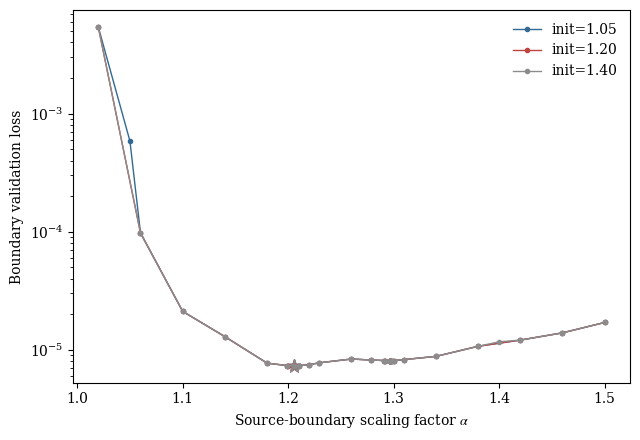

已保存结果： C:\Users\magic\Desktop\KM-PIKFNN\方板受压\adaptive_source_results


,mode,alpha_initial,alpha_final,train_loss,validation_loss,coefficient_norm,effective_rank,effective_condition,regularization_rel,objective_evaluations,time_s,L2_ux,L2_uy,L2_von_mises
0,fixed,1.05,1.050000,0.000295,0.000586,5.965455,198,4.607517e+03,1.000000e-08,1,0.150710,0.011283,0.001046,0.015702
1,fixed,1.10,1.100000,0.000013,0.000021,13.017449,198,1.923357e+04,1.000000e-08,1,0.139774,0.003082,0.000410,0.004653
2,fixed,1.20,1.200000,0.000004,0.000007,743.985559,198,5.469996e+06,1.000000e-08,1,0.139416,0.001908,0.000236,0.002100
3,fixed,1.30,1.300000,0.000004,0.000008,12680.369648,188,8.952330e+07,1.000000e-08,1,0.132957,0.002264,0.000265,0.002553
4,fixed,1.40,1.400000,0.000007,0.000012,15416.793177,172,7.081044e+07,1.000000e-08,1,0.131438,0.002598,0.000317,0.003291
5,adaptive,1.05,1.205499,0.000004,0.000007,944.585815,198,7.283190e+06,1.000000e-08,32,4.074492,0.001888,0.000234,0.002062
6,adaptive,1.20,1.205499,0.000004,0.000007,944.585815,198,7.283190e+06,1.000000e-08,32,3.978770,0.001888,0.000234,0.002062
7,adaptive,1.40,1.205499,0.000004,0.000007,944.585815,198,7.283190e+06,1.000000e-08,32,4.015508,0.001888,0.000234,0.002062


,Quantity,Fixed alpha=1.05,Fixed alpha=1.10,Fixed alpha=1.20,Fixed alpha=1.30,Fixed alpha=1.40,Adaptive (init=1.05)
0,alpha_initial,1.050000,1.100000,1.200000,1.300000,1.400000,1.050000
1,alpha_final,1.050000,1.100000,1.200000,1.300000,1.400000,1.205499
2,L2_ux,0.011283,0.003082,0.001908,0.002264,0.002598,0.001888
3,L2_uy,0.001046,0.000410,0.000236,0.000265,0.000317,0.000234
4,L2_von_mises,0.015702,0.004653,0.002100,0.002553,0.003291,0.002062
5,time_s,0.150710,0.139774,0.139416,0.132957,0.131438,4.074492


In [3]:
# 先运行上面的BEM单元，或改为COMSOL参考。参考只参与事后评价。
REFERENCE_KIND = "BEM"          # "BEM" / "COMSOL" / "NONE"
COMSOL_REF_PATH = r"C:\Users\magic\Desktop\KM-PIKFNN\方板受压\方板受压comsol.txt"
if REFERENCE_KIND == "BEM":
    if not all(name in globals() for name in ["internal_pts", "u_int", "von_mises"]):
        raise RuntimeError("先运行BEM单元，或选择COMSOL/NONE。")
    reference_points = np.asarray(internal_pts, dtype=np.float64)
    reference_fields = {"ux": u_int[:, 0], "uy": u_int[:, 1], "von_mises": von_mises}
elif REFERENCE_KIND == "COMSOL":
    reference_points, reference_fields = load_comsol_reference(COMSOL_REF_PATH)
elif REFERENCE_KIND == "NONE":
    reference_points, reference_fields = None, None
else:
    raise ValueError("REFERENCE_KIND只能为BEM、COMSOL或NONE。")
experiment_rows, adaptive_model, adaptive_runs = run_experiment(
    reference_points, reference_fields, output_dir=Path.cwd()/"adaptive_source_results")
try:
    from IPython.display import display
except ImportError:
    display = print
try:
    import pandas as pd
    display(pd.DataFrame(experiment_rows))
    display(pd.read_csv(Path.cwd()/"adaptive_source_results"/"table1.csv"))
except ImportError:
    for row in experiment_rows:
        print(row)


## 自适应模型物理场

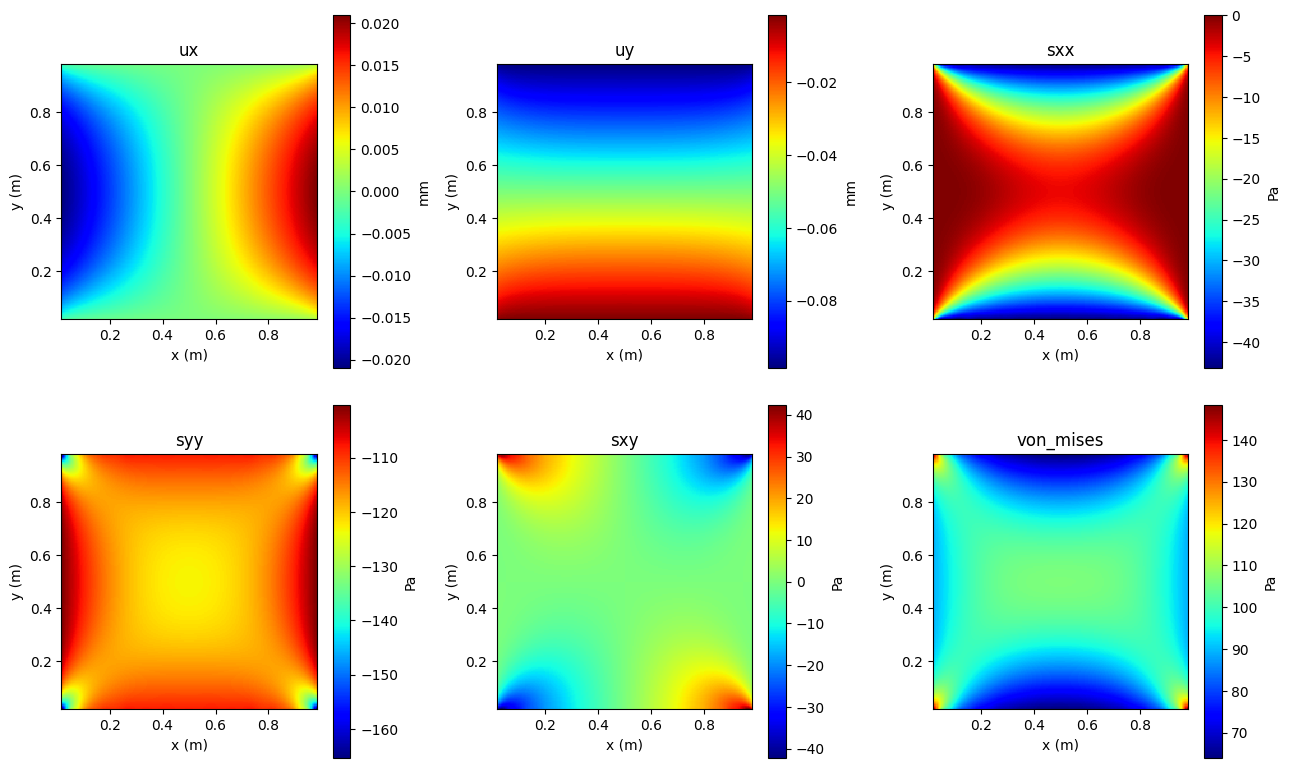

In [4]:
# 自适应配置的六物理量云图；无需PyTorch model变量。
grid = np.linspace(0.02, 0.98, 200)
xx, yy = np.meshgrid(grid, grid)
points = np.column_stack((xx.ravel(), yy.ravel()))
fields = predict_fields(adaptive_model, points)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, key in zip(axes.ravel(), ["ux", "uy", "sxx", "syy", "sxy", "von_mises"]):
    scale = 1e3 if key in ("ux", "uy") else 1.0
    im = ax.pcolormesh(xx, yy, (fields[key]*scale).reshape(xx.shape), shading="auto", cmap="jet")
    ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_title(key)
    fig.colorbar(im, ax=ax, label="mm" if scale==1e3 else "Pa")
fig.tight_layout()
fig.savefig(Path.cwd()/"adaptive_source_results"/"adaptive_fields.png", dpi=300)
plt.show()
